# The `.chromdata.zarr` store

A `ChromData` lives on disk as a `.chromdata.zarr` store (Zarr v3 + Parquet; `.cdz` is the same tree in one
zip file).  The store is laid out so that a cell, a trace or a chromosome can be read alone — from a local
disk or over HTTP — and data larger than memory can be written and processed in pieces.  Contact maps and
expression matrices stay in their own files and are *linked*; for a self-contained store (an atlas on object
storage) they can be *embedded*.

**Modules**: `chromdata` (`ChromData.write` / `read` / `writer`, `chromdata.settings`,
`chromdata.embedded`, `chromdata.catalog`).
**Data**: Takei et al. 2021, *Nature* 590:344 (DNA seqFISH+, 201 mouse ES cells): the 4DN FOF-CT core table
`4DNFIHF3JCBY.csv` and its cell table `4DNFIFINA2U9.csv`, which `ds.fetch("takei")` / `ds.fetch("takei_tables")`
download once from 4DN (23 MB); Stevens et al. 2017, *Nature* 544:59 (8 haploid mouse ES cells: published
NucDynamics structures, 10 models per cell, with their single-cell Hi-C contacts as `.scool` / `.mcool`): the
store of the public U-Chrom atlas, `ds.atlas("stevens2017_mesc")` (26 MB; built by
`apps/atlas/recipes/build_stevens2017.py` from GEO GSE80280), read over HTTP and copied to `_out/` with its
contact maps; and three more atlas stores read over HTTP (HiRES mouse embryo: Liu et al. 2023, *Science*,
doi:10.1126/science.adg3797; Takei 2025 cerebellum: Takei et al. 2025, *Nature*, doi:10.1038/s41586-025-08838-x;
scHiCAR mouse cortex, GEO GSE305439).  **Runtime**: about 1.5 min, most of it reading over HTTP.
The data model itself is the subject of `chromdata_basics`.

In [1]:
import json
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chromdata
import uchrom.datasets as ds
from chromdata import ChromData

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out") / "chromdata_stores"            # outputs: tutorials/_out/ (ignored by git)
shutil.rmtree(OUT, ignore_errors=True); OUT.mkdir(parents=True)

CORE = ds.fetch("takei")                            # Takei 2021 FOF-CT core table (4DN, 22 MB; downloaded once)
CELLS = ds.fetch("takei_tables") / "4DNFIFINA2U9.csv"   # ... and its cell table (4DN)


def size(path):
    # bytes of a file or a directory tree
    path = Path(path)
    return path.stat().st_size if path.is_file() else sum(f.stat().st_size for f in path.rglob("*") if f.is_file())


def timed(fn, *args, repeat=3, **kwargs):
    # (result, best wall time in s of `repeat` calls)
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); out = fn(*args, **kwargs); best = min(best, time.perf_counter() - t0)
    return out, best


print("chromdata", chromdata.__version__)

chromdata 0.1.0


## `write` and `read`

The container follows the suffix: `<name>.chromdata.zarr` is a directory, `<name>.cdz` the same tree in one
uncompressed zip file (one file to download or attach).  Writers are atomic (a temporary sibling, then a
rename).  The Takei 2021 table with its cell table:

In [2]:
cd = ChromData.from_fofct(CORE, cell_table=CELLS)
print(cd.n_cells, "cells,", cd.n_traces, "traces,", cd.n_spots, "spots,", cd.n_bins, "bins")

rows = []
for name in ("takei2021.chromdata.zarr", "takei2021.cdz"):
    path = OUT / name
    t0 = time.perf_counter(); cd.write(path); t_write = time.perf_counter() - t0
    back, t_read = timed(ChromData.read, path)
    rows.append({"file": name, "MB": size(path) / 1e6, "write s": t_write, "read s": t_read})
rows.append({"file": f"{CORE.name} (FOF-CT csv)", "MB": size(CORE) / 1e6, "write s": np.nan,
             "read s": timed(ChromData.from_fofct, CORE, cell_table=CELLS, repeat=1)[1]})
pd.DataFrame(rows).set_index("file").round(3)

201 cells, 8285 traces, 316995 spots, 1200 bins


,MB,write s,read s
file,,,
takei2021.chromdata.zarr,4.811,1.985,0.027
takei2021.cdz,4.790,0.431,0.028
4DNFIHF3JCBY.csv (FOF-CT csv),21.859,NaN,0.309


Every spot comes back with its values; check after sorting both sides by `spot_id`:

In [3]:
def by_spot(x):
    return np.argsort(x.spots["spot_id"].to_numpy())

a, b = by_spot(cd), by_spot(back)
print("coords:", np.array_equal(cd.coords[a], back.coords[b]),
      "| spots:", cd.spots.iloc[a].reset_index(drop=True).equals(back.spots.iloc[b].reset_index(drop=True)),
      "| bins:", cd.bins.equals(back.bins), "| cells:", cd.cells.equals(back.cells),
      "| uns:", json.dumps(cd.uns, sort_keys=True, default=str) == json.dumps(back.uns, sort_keys=True, default=str))

coords: True | spots: True | bins: True | cells: True | uns: True


### Row order and `original_order=True`

The writer sorts the spots — by cell, trace, chromosome and bin (the order of the categories; trace
`0_1_10_0` sorts before `0_1_1_0`) — so that a cell or a trace is one contiguous slice.  A read returns that
order.  The store also keeps each spot's original row (`index/source_row`); `original_order=True` restores
the order of the object that was written.

In [4]:
cols = ["trace_id", "cell_id", "spot_id", "chrom", "start"]
print("in memory (file order):"); print(cd.spots[cols].head(3).to_string())
print("read back (stored order):"); print(back.spots[cols].head(3).to_string())
same = ChromData.read(OUT / "takei2021.chromdata.zarr", original_order=True)
print("original_order=True: spots equal:", same.spots.equals(cd.spots), "| coords equal:", np.array_equal(same.coords, cd.coords))

in memory (file order):
  trace_id cell_id  spot_id chrom      start
0  0_1_1_0     0_1   705144  chr1  135625000
1  0_1_1_0     0_1   705145  chr1  135650000
2  0_1_1_1     0_1   705146  chr1  135650000
read back (stored order):
   trace_id cell_id  spot_id  chrom     start
0  0_1_10_0     0_1   705835  chr10  75425000
1  0_1_10_0     0_1   705837  chr10  75450000
2  0_1_10_0     0_1   705839  chr10  75475000
original_order=True: spots equal: True | coords equal: True


### The layout in brief

Everything with rows is Parquet, everything n-dimensional a Zarr array, metadata are JSON attributes.  Each
spot-aligned value is stored once: coordinates and the key columns in `tables/coords/`, **partitioned by
chromosome** (`chrom=<name>/part-0.parquet`, sorted by cell, trace and bin); every other spot column in
cell-sorted *primary* tables (`tables/primary/`); `index/` holds the row offsets of every (cell, trace,
chromosome) run, which is what lets a reader fetch one cell or one chromosome alone.  The full specification
is `packages/chromdata/spec.md`.  `write()` options: `coord_dtype="float32"` (coordinates stored as float32,
float64 in memory), `row_group_rows`, `compression_level`.

In [5]:
store = OUT / "takei2021.chromdata.zarr"
for p in sorted(store.iterdir()):
    n = sum(1 for _ in p.rglob("*")) if p.is_dir() else 1
    print(f"{p.name + ('/' if p.is_dir() else ''):14s} {size(p) / 1e6:6.2f} MB  {n:3d} entries")
parts = sorted((store / "tables" / "coords").iterdir())
print(len(parts), "coordinate partitions, e.g.", [p.name for p in parts[:3]])
attrs = json.loads((store / "zarr.json").read_text())["attributes"]
print({k: attrs[k] for k in ("uchrom_format_version", "uchrom_version")},
      {k: attrs["uchrom"][k] for k in ("layout", "spot_order", "coords_order", "n_spots", "n_cells")})

binm/            0.00 MB    1 entries
cellm/           0.00 MB    1 entries
contacts/        0.00 MB    1 entries
index/           0.47 MB   83 entries
links/           0.00 MB    1 entries
results/         0.00 MB    1 entries
tables/          4.30 MB   51 entries
uns/             0.00 MB    1 entries
zarr.json        0.03 MB    1 entries
20 coordinate partitions, e.g. ['chrom=chr1', 'chrom=chr10', 'chrom=chr11']
{'uchrom_format_version': '2.3', 'uchrom_version': '0.2.0'} {'layout': 'primary+coords', 'spot_order': 'cell,trace,chrom,bin', 'coords_order': 'chrom,cell,trace,bin', 'n_spots': 316995, 'n_cells': 201}


A partition is a plain Parquet file (trace and cell ids as integer codes into `tables/categories/`), so
pandas, Arrow, DuckDB or Polars can read the store without `chromdata`:

In [6]:
chr3 = pd.read_parquet(store / "tables" / "coords" / "chrom=chr3" / "part-0.parquet")
print(chr3.shape, dict(chr3.dtypes.astype(str)))
chr3.head(3)

(18150, 6) {'bin_id': 'int32', 'trace_id': 'int16', 'cell_id': 'int16', 'x': 'float64', 'y': 'float64', 'z': 'float64'}


,bin_id,trace_id,cell_id,x,y,z
0,720,434,0,171.151,18.165,2.530
1,721,434,0,171.100,18.199,2.446
2,723,434,0,171.057,18.220,2.574


## A local copy of an atlas store

The Stevens 2017 store of the public atlas holds 8 cells × ~25,700 particles of 100 kb with **ten** models per
cell — model 1 in `coords`, models 2–10 as `layers`, 10 coordinate sets per spot — and two contact maps of the
same cells: one per cell (1 Mb) and the merged map of the 8 cells.  `ds.atlas("stevens2017_mesc")` opens it
over HTTP, backed (more in the last section).  The local sections below need it on disk the way
`apps/atlas/recipes/build_stevens2017.py` leaves it: the store, and next to it the two cooler files it *links*.
`to_memory()` reads everything over HTTP and `write` makes the local store; the atlas store also carries
*embedded* copies of the two maps (see below), which `chromdata.embedded.export_scool` / `export_mcool` write
back to the cooler files the link records name:

In [7]:
from chromdata.embedded import export_mcool, export_scool

remote = ds.atlas("stevens2017_mesc")                   # backed, over HTTP
url = ds.list_atlas().loc["stevens2017_mesc", "url"]
STEVENS = OUT / "stevens2017_mesc"; STEVENS.mkdir()
SPATH = STEVENS / "stevens2017_mesc.chromdata.zarr"

t0 = time.perf_counter()
remote.to_memory().write(SPATH)                         # coordinates, the 10 models, tables, link records
t_copy = time.perf_counter() - t0
for key, rec in remote.uns["linked_scool"].items():    # one map per cell -> .scool
    export_scool(url, key, STEVENS / rec["path"])
for key, rec in remote.uns["linked_cool"].items():     # the merged map -> .mcool
    export_mcool(url, key, STEVENS / rec["path"])
print(f"store read over HTTP and written in {t_copy:.0f} s; maps exported in {time.perf_counter() - t0 - t_copy:.0f} s")
for p in sorted(STEVENS.iterdir()):
    print(f"  {p.name:36s} {size(p) / 1e6:5.1f} MB")

store read over HTTP and written in 14 s; maps exported in 37 s
  stevens2017_mesc.chromdata.zarr       23.1 MB
  stevens2017_mesc_bulk.mcool            1.1 MB
  stevens2017_mesc_cells_1Mb.scool       0.5 MB


## Reading part of a store

`columns=` / `tracks=` choose the spot-aligned columns to read: `columns="coords"` reads coordinates and keys
only, a list adds the named spot columns, spot tracks or layers.  On the local Stevens 2017 store:

In [8]:
SPATH = STEVENS / "stevens2017_mesc.chromdata.zarr"
full, t_full = timed(ChromData.read, SPATH)
print(f"{SPATH.name}: {size(SPATH / 'tables') / 1e6:.1f} MB of tables; {full.n_cells} cells, {full.n_spots:,} spots, "
      f"layers {list(full.layers)[:2]} ... {list(full.layers)[-1]}")
sel = {"everything": None, 'columns="coords"': "coords", 'columns=["model_2"]': ["model_2"]}
pd.DataFrame([{"read": k, "s": timed(ChromData.read, SPATH, columns=v)[1],
               "layers": len(ChromData.read(SPATH, columns=v).layers)} for k, v in sel.items()]).set_index("read").round(3)

stevens2017_mesc.chromdata.zarr: 23.1 MB of tables; 8 cells, 205,706 spots, layers ['model_2', 'model_3'] ... model_10


,s,layers
read,,
everything,0.087,9
"columns=""coords""",0.036,0
"columns=[""model_2""]",0.042,1


## Backed mode

`read(path, backed=True)` loads only the small tables (bins, cells, traces, uns, results, …).  `coords`,
`spots`, `spot_tracks` and `layers` stay on disk as proxies; `get_cell` / `get_trace` / `get_chrom` /
`cd[rows]` read only the row ranges they need and return ordinary in-memory `ChromData` objects.

In [9]:
bk, t_open = timed(ChromData.read, SPATH, backed=True)
print(f"open backed: {t_open * 1e3:.0f} ms (full read {t_full * 1e3:.0f} ms)")
print(bk.coords, "|", bk.layers["model_2"])
print(bk.spots)
print("first rows read on access:", bk.coords[:2].round(2).tolist())

ops = {
    'get_cell("Cell_3")': lambda: bk.get_cell("Cell_3"),
    'get_cell("Cell_3", columns="coords")': lambda: bk.get_cell("Cell_3", columns="coords"),
    'get_trace("Cell_3_chr7", columns="coords")': lambda: bk.get_trace("Cell_3_chr7", columns="coords"),
    'get_chrom("chr2", columns="coords")': lambda: bk.get_chrom("chr2", columns="coords"),
    "bk[100_000:101_000]": lambda: bk[100_000:101_000],
}
table = []
for name, fn in ops.items():
    sub, t = timed(fn)
    table.append({"call": name, "ms": t * 1e3, "n_spots": sub.n_spots, "layers": len(sub.layers),
                  "in memory": type(sub).__name__ == "ChromData"})
pd.DataFrame(table).set_index("call").round(1)

open backed: 16 ms (full read 85 ms)
<BackedArray spots shape=(205706, 3)> | <BackedArray layers/model_2 shape=(205706, 3)>
<BackedFrame spots: 205706 rows x 6 columns ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']>
first rows read on access: [[9.94, -6.49, -1.41], [9.19, -7.26, -0.92]]


,ms,n_spots,layers,in memory
call,,,,
"get_cell(""Cell_3"")",5.4,25717,9,True
"get_cell(""Cell_3"", columns=""coords"")",3.9,25717,0,True
"get_trace(""Cell_3_chr7"", columns=""coords"")",1.2,1423,0,True
"get_chrom(""chr2"", columns=""coords"")",1.9,14323,0,True
bk[100_000:101_000],3.3,1000,9,True


The backed object is read-only for spot-aligned data; `to_memory()` (optionally with `columns=`) loads an
editable copy.  Results and intervals computed on subsets are written back to an in-memory object.

In [10]:
try:
    bk.coords = np.zeros((3, 3))
except AttributeError as err:
    print("AttributeError:", err)
mem = bk.to_memory(columns="coords")
print(type(mem).__name__, mem.n_spots, "spots,", len(mem.layers), "layers")

AttributeError: backed ChromData is read-only for spot-aligned data (coords, spots, spot_tracks, layers); call cd.to_memory() for an editable copy
ChromData 205706 spots, 0 layers


### Streaming: `iter_cells`, `iter_traces` and the memory budget

`iter_cells(batch=)` / `iter_traces(batch=)` yield in-memory chunks of whole cells / traces; backed and
in-memory objects yield identical chunks.  `batch="auto"` sizes the chunks from
`chromdata.settings.memory_budget` (default: half of the available RAM; `uchrom.settings` is the same
object), which also bounds the streaming writer and the streaming callers of `uchrom`.

In [11]:
print(chromdata.settings)
nbytes = full.coords.nbytes * (1 + len(full.layers))
print(f"all 10 models in memory: {nbytes / 1e6:.0f} MB of coordinates")
rows = []
for budget in ("16MB", "64MB", "1GB"):
    chromdata.settings.memory_budget = budget
    chunks = [c.n_spots for c in bk.iter_traces(batch="auto")]
    rows.append({"memory_budget": budget, "chunks": len(chunks), "largest chunk (spots)": max(chunks)})
chromdata.settings.memory_budget = None          # back to the default
display(pd.DataFrame(rows).set_index("memory_budget"))

same_chunks = all(np.array_equal(x.coords, y.coords) and x.spots.equals(y.spots)
                  for x, y in zip(full.iter_cells(batch=3), bk.iter_cells(batch=3)))
print("iter_cells(batch=3): in-memory and backed chunks identical:", same_chunks)

chromdata.settings(memory_budget=11.4 GB (default), default_batch='auto')
all 10 models in memory: 49 MB of coordinates


,chunks,largest chunk (spots)
memory_budget,,
16MB,54,5775
64MB,11,24837
1GB,1,205706


iter_cells(batch=3): in-memory and backed chunks identical: True


A streaming computation reads one chunk at a time.  Structure precision per cell — the RMSD between model 1
and model 2 after optimal superposition (Kabsch) — needs only `coords` and the layer `model_2`:

In [12]:
def rmsd(a, b):
    # RMSD (input units) of b onto a after translation + rotation
    a0, b0 = a - a.mean(0), b - b.mean(0)
    u, _, vt = np.linalg.svd(b0.T @ a0)
    u[:, -1] *= np.sign(np.linalg.det(u @ vt))          # a proper rotation, no reflection
    return float(np.sqrt(((b0 @ u @ vt - a0) ** 2).sum(1).mean()))

t0 = time.perf_counter()
prec = {}
for chunk in bk.iter_cells(batch=1, columns=["model_2"]):
    prec[str(chunk.spots["cell_id"].iloc[0])] = rmsd(chunk.coords, chunk.layers["model_2"])
print(f"{time.perf_counter() - t0:.2f} s; RMSD model 1 vs 2 (particle radii):",
      {k: round(v, 2) for k, v in prec.items()})

0.04 s; RMSD model 1 vs 2 (particle radii): {'Cell_1': 0.53, 'Cell_2': 0.98, 'Cell_3': 0.98, 'Cell_4': 1.0, 'Cell_5': 1.42, 'Cell_6': 1.42, 'Cell_7': 2.99, 'Cell_8': 1.92}


## Writing larger-than-memory data: `ChromData.writer`

The streaming writer takes chunks — `ChromData` objects, or `coords=` + `spots=` (+ `spot_tracks=`) — spills
them to disk sorted by chromosome and cell, and on `finish()` merges each chromosome in pieces that fit the
memory budget.  The result is the same store `ChromData(...).write()` produces for the concatenated input.
Here the Takei 2021 core table is read in 50,000-row pandas chunks:

In [13]:
with open(CORE) as fh:
    header = [line for line in fh if line.lstrip('"').startswith("#")]
names = next(l for l in header if l.startswith("##columns=")).split("=", 1)[1].strip().strip(",").strip("()").split(",")

t0 = time.perf_counter()
with ChromData.writer(OUT / "takei2021_streamed.chromdata.zarr", memory_budget="64MB") as w:
    for chunk in pd.read_csv(CORE, skiprows=len(header), header=None, names=names, chunksize=50_000):
        spots = pd.DataFrame({"chrom": chunk["Chrom"], "start": chunk["Chrom_Start"], "end": chunk["Chrom_End"],
                              "trace_id": chunk["Trace_ID"], "spot_id": chunk["Spot_ID"], "cell_id": chunk["Cell_ID"],
                              "extra_cell_roi_id": chunk["Extra_Cell_ROI_ID"]})
        w.append(coords=chunk[["X", "Y", "Z"]].to_numpy(), spots=spots)
    w.finish(cells=cd.cells, uns={"genome_assembly": "GRCm38/mm10", "xyz_unit": "micron"})
print(f"streamed {w.n_spots:,} spots in {time.perf_counter() - t0:.1f} s")

streamed = ChromData.read(OUT / "takei2021_streamed.chromdata.zarr")
print("same as the in-memory write: coords", np.array_equal(streamed.coords, back.coords),
      "| spots", streamed.spots.equals(back.spots), "| bins", streamed.bins.equals(back.bins),
      "| cells", streamed.cells.equals(back.cells))

streamed 316,995 spots in 1.2 s
same as the in-memory write: coords True | spots True | bins True | cells True


`from_fofct(..., out=)` does exactly this for FOF-CT tables (companion tables included) and returns the store
opened backed; the seqFISH+ multi-omics loader of `uchrom.io` has the same `out=` option.

In [14]:
t0 = time.perf_counter()
fofct_backed = ChromData.from_fofct(CORE, cell_table=CELLS, out=OUT / "takei2021_from_fofct.chromdata.zarr",
                                    chunksize=50_000, memory_budget="64MB")
print(f"{time.perf_counter() - t0:.1f} s ->", type(fofct_backed).__name__, f"{fofct_backed.n_spots:,} spots")
m = fofct_backed.to_memory()
print("equal to the in-memory import:", np.array_equal(m.coords, back.coords), m.spots.equals(back.spots), m.cells.equals(back.cells))

1.3 s -> BackedChromData 316,995 spots
equal to the in-memory import: True True True


## Linked modalities

Contacts and expression matrices are not copied into a ChromData: the store records a **link** (path +
metadata) in `uns` and the file stays where it is.  `link_cool` (one bulk / pseudo-bulk map, `.cool` /
`.mcool`) and `link_scool` (one map per cell) write the records; relative paths resolve against the
directory of the store, so a dataset folder can be moved as a whole.  The Stevens 2017 store links its
cells' contacts (1 Mb per cell) and the merged map of the 8 cells — the two files next to it:

In [15]:
print(json.dumps({k: full.uns[k] for k in ("linked_cool", "linked_scool")}, indent=1))
print("validate_links():", full.validate_links())

{
 "linked_cool": {
  "bulk": {
   "path": "stevens2017_mesc_bulk.mcool",
   "format": "mcool",
   "label": "All 8 cells (merged)",
   "genome_assembly": "mm10"
  }
 },
 "linked_scool": {
  "per_cell": {
   "path": "stevens2017_mesc_cells_1Mb.scool",
   "format": "scool",
   "cell_name": "cell_id",
   "genome_assembly": "mm10",
   "bin_size": 1000000,
   "coordinate_status": "contacts, not xyz coordinates",
   "label": "Per cell"
  }
 }
}
validate_links(): []


`load_linked_scool()` lists the cells; with `cell=` it returns a `cooler.Cooler`, and `linked_cool_path()`
the path of the bulk map.  Contacts and coordinates of one cell side by side: in the published structure of
Cell 1, chromatin regions that were in contact are much closer than regions at the same genomic distance
that were not.

In [16]:
import cooler

print(full.load_linked_scool(key="per_cell")["cells"][:3], "...")
print("bulk map:", os.path.relpath(full.linked_cool_path("bulk")), cooler.fileops.list_coolers(full.linked_cool_path("bulk")))

clr = full.load_linked_scool(key="per_cell", cell="Cell_1")
cell1 = full.get_cell("Cell_1", columns="coords")
ratio = {}
for chrom in ("chr1", "chr2", "chr5", "chr11", "chr19"):
    sub = cell1.get_chrom(chrom)
    mb = sub.spots["start"].to_numpy() // 1_000_000                 # 100 kb particles -> 1 Mb bins
    contacts = clr.matrix(balance=False).fetch(chrom)
    pos = np.full((len(contacts), 3), np.nan)
    means = pd.DataFrame(sub.coords).groupby(mb).mean()
    pos[means.index] = means.to_numpy()
    dist = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    i, j = np.triu_indices(len(contacts), k=2)
    keep = np.isfinite(dist[i, j]) & (j - i <= 20)                   # pairs 2-20 Mb apart
    hit = contacts[i, j] > 0
    ratio[chrom] = float(np.median(dist[i, j][keep & hit]) / np.median(dist[i, j][keep & ~hit]))
print("median 3-D distance, contacted / not contacted (2-20 Mb apart):", {k: round(v, 2) for k, v in ratio.items()})

['/cells/Cell_1', '/cells/Cell_2', '/cells/Cell_3'] ...
bulk map: _out/chromdata_stores/stevens2017_mesc/stevens2017_mesc_bulk.mcool ['/resolutions/100000', '/resolutions/500000', '/resolutions/1000000']
median 3-D distance, contacted / not contacted (2-20 Mb apart): {'chr1': 0.43, 'chr2': 0.44, 'chr5': 0.46, 'chr11': 0.41, 'chr19': 0.52}


A copy written somewhere else keeps the link records verbatim, so relative links break — `validate_links()`
says so.  Re-link with paths relative to the new location (absolute paths work too):

In [17]:
copy_path = OUT / "stevens2017.chromdata.zarr"
full.write(copy_path)
copy = ChromData.read(copy_path)
print("after copying:", copy.validate_links())

relto = lambda p: os.path.relpath(Path(p).resolve(), copy_path.parent.resolve())
copy.link_cool(relto(STEVENS / "stevens2017_mesc_bulk.mcool"), key="bulk", label="All 8 cells (merged)")
copy.link_scool(relto(STEVENS / "stevens2017_mesc_cells_1Mb.scool"), key="per_cell", label="Per cell",
                cell_name="cell_id", genome_assembly="mm10", bin_size=1_000_000)
copy.write(copy_path)
copy = ChromData.read(copy_path, backed=True)
print("re-linked:", copy.uns["linked_scool"]["per_cell"]["path"], "| validate_links():", copy.validate_links())

after copying: ['linked_scool.per_cell path does not exist: stevens2017_mesc_cells_1Mb.scool', 'linked_cool.bulk path does not exist: stevens2017_mesc_bulk.mcool']


re-linked: stevens2017_mesc/stevens2017_mesc_cells_1Mb.scool | validate_links(): []


### AnnData: copy the cell table, or link the file

For cell-by-feature matrices there are two routes.  `link_anndata(adata)` copies `obs` / `obsm` into
`cells` / `cellm` (matched by `cell_id`); a record `uns["linked_anndata"]` instead points at the `.h5ad`,
which is opened lazily as `cd.linked_adata`.  The Takei 2021 mRNA counts (45 genes, cell table) as an AnnData:

In [18]:
import anndata as ad

genes = [c for c in cd.cells.columns if c.startswith("rna.")]
X = cd.cells[genes].to_numpy(float)
logx = np.log1p(X / X.sum(1, keepdims=True) * 1e4)
u, s, _ = np.linalg.svd(logx - logx.mean(0), full_matrices=False)
adata = ad.AnnData(X=X, obs=cd.cells[["nucleus_area_um2", "keep1"]].copy(),
                   var=pd.DataFrame(index=[g.removeprefix("rna.") for g in genes]), obsm={"X_pca": u[:, :10] * s[:10]})
adata.write_h5ad(OUT / "takei2021_rna.h5ad")

core = ChromData.from_fofct(CORE)                    # spots only, no cell table
print("matched cells:", core.link_anndata(adata), "| cells:", list(core.cells.columns), "| cellm:", list(core.cellm))
core.uns["linked_anndata"] = {"path": "takei2021_rna.h5ad", "format": "h5ad"}
core.write(OUT / "takei2021_rna.chromdata.zarr")
rna_store = ChromData.read(OUT / "takei2021_rna.chromdata.zarr", backed=True)
print("validate_links():", rna_store.validate_links(), "| linked_adata:", rna_store.linked_adata.shape)

matched cells: 201 | cells: ['nucleus_area_um2', 'keep1'] | cellm: ['X_pca']


validate_links(): [] | linked_adata: (201, 45)


## Embedded copies: `chromdata.embedded`

A store on object storage cannot follow links to files on someone's disk.  `embed_links(store)` (or
`python -m chromdata.embedded STORE`) copies every linked `.cool` / `.mcool` / `.scool` / `.h5ad` into the
store (`embedded/contacts/<key>/`, `embedded/anndata/<key>/`): pixels as Zarr arrays partitioned by
chromosome and sharded for range reads.  The link records stay; readers use the embedded copy when the file
is not there.

In [19]:
from chromdata.embedded import EmbeddedContacts, embed_links

before = size(copy_path)
t0 = time.perf_counter()
done = embed_links(copy_path)
done_rna = embed_links(OUT / "takei2021_rna.chromdata.zarr")
print(f"embedded {list(done)} + {list(done_rna)} in {time.perf_counter() - t0:.1f} s; "
      f"store {before / 1e6:.1f} -> {size(copy_path) / 1e6:.1f} MB "
      f"(linked files: {(size(STEVENS / 'stevens2017_mesc_bulk.mcool') + size(STEVENS / 'stevens2017_mesc_cells_1Mb.scool')) / 1e6:.1f} MB)")
emb = ChromData.read(copy_path, backed=True)
print(emb.embedded_links())

[embed] linked_cool/bulk: stevens2017_mesc_bulk.mcool


[embed] linked_scool/per_cell: stevens2017_mesc_cells_1Mb.scool


[embed] linked_anndata/default: takei2021_rna.h5ad


embedded ['bulk', 'per_cell'] + ['default'] in 1.9 s; store 23.1 -> 25.2 MB (linked files: 1.6 MB)
{'contacts': {'bulk': 'bulk', 'per_cell': 'per_cell'}, 'anndata': {}, 'images': {}}


`EmbeddedContacts` reads an embedded map directly — one cell's pixels of one chromosome are one contiguous
slice.  They are exactly the pixels of the `.scool`:

In [20]:
per_cell = EmbeddedContacts(str(copy_path), emb.embedded_links()["contacts"]["per_cell"])
print(per_cell.kind, per_cell.resolutions, len(per_cell.cells), "cells,", len(per_cell.chroms), "chromosomes")
pix = per_cell.cell_pixels("cis/chr1", [per_cell.cells.index("Cell_1")])          # (bin1, bin2, count), chromosome-local
ref = clr.matrix(balance=False, as_pixels=True).fetch("chr1")
print(f"Cell_1 chr1: {len(pix)} pixels, {pix[:, 2].sum()} contacts; identical to the scool:",
      np.array_equal(pix[:, 2], ref["count"].to_numpy()) and np.array_equal(pix[:, 0] + per_cell.first_bin("chr1"), ref["bin1_id"].to_numpy()))

per_cell [1000000] 8 cells, 20 chromosomes
Cell_1 chr1: 995 pixels, 7579 contacts; identical to the scool: True


Now ship the store alone — moved to a folder without the linked files.  The links no longer resolve, but
nothing is missing: `validate_links()` is clean, `load_linked_scool(cell=)` / `linked_cool_path()` export
cooler files from the embedded pixels on demand, and `linked_adata` reads the embedded AnnData.

In [21]:
shipped = OUT / "shipped"; shipped.mkdir()
shutil.copytree(copy_path, shipped / copy_path.name)
shutil.copytree(OUT / "takei2021_rna.chromdata.zarr", shipped / "takei2021_rna.chromdata.zarr")
alone = ChromData.read(shipped / copy_path.name, backed=True)
rec = alone.uns["linked_cool"]["bulk"]["path"]
print("link resolves:", alone.resolve_link_path(rec).exists(), "| validate_links():", alone.validate_links())

one, t = timed(alone.load_linked_scool, key="per_cell", cell="Cell_1", repeat=1)
print(f"Cell_1 exported from the embedded copy in {t:.2f} s:", np.array_equal(one.matrix(balance=False).fetch("chr1"),
                                                                              clr.matrix(balance=False).fetch("chr1")))
mcool = alone.linked_cool_path("bulk")
orig = cooler.Cooler(f"{full.linked_cool_path('bulk')}::/resolutions/1000000")
again = cooler.Cooler(f"{mcool}::/resolutions/1000000")
print("bulk mcool exported:", cooler.fileops.list_coolers(mcool), "| chr2 balanced matrix identical:",
      np.allclose(orig.matrix().fetch("chr2"), again.matrix().fetch("chr2"), equal_nan=True))
rna_alone = ChromData.read(shipped / "takei2021_rna.chromdata.zarr", backed=True)
print("AnnData from the embedded copy:", rna_alone.linked_adata.shape, np.array_equal(rna_alone.linked_adata.X, adata.X))

link resolves: False | validate_links(): []
Cell_1 exported from the embedded copy in 0.15 s: True


bulk mcool exported: ['/resolutions/100000', '/resolutions/500000', '/resolutions/1000000'] | chr2 balanced matrix identical: True
AnnData from the embedded copy: (201, 45) True


## The public atlas over HTTP

The U-Chrom atlas is a bucket of embedded stores plus a `catalog.json`.  `chromdata.catalog.fetch_catalog`
reads the catalog; `ChromData.read(url, backed=True)` opens any store over HTTP (fsspec; `s3://` and `gs://`
work too) — metadata and small tables at open, range requests afterwards.  Remote stores are always read
backed.

In [22]:
from chromdata.catalog import DEFAULT_ATLAS, fetch_catalog

catalog = fetch_catalog(DEFAULT_ATLAS)
print(DEFAULT_ATLAS, "| updated", catalog["updated"], "|", len(catalog["datasets"]), "datasets")
atlas = pd.DataFrame(catalog["datasets"]).set_index("id")
atlas["modalities"] = atlas["modalities"].str.join(", ")
atlas[["n_cells", "n_spots", "size_mb", "modalities"]].sort_values("size_mb", ascending=False).head(8)

https://uchrom-atlas-r2.u-science.org | updated 2026-10-06T00:22:29Z | 22 datasets


,n_cells,n_spots,size_mb,modalities
id,,,,
hicrna_mouse_embryo,64861,0,4577.6,"Hi-C per spot, Hi-C bulk, RNA, images, embeddings"
hires_embryo,7469,182344800,3174.2,"Hi-C per cell, Hi-C bulk, RNA, 3-D coordinates..."
hicrna_human_melanoma,12649,0,2727.7,"Hi-C per spot, Hi-C bulk, RNA, images, embeddings"
dschic_aging_cortex,32777,0,2277.9,"Hi-C per cell, Hi-C bulk, embeddings"
hicrna_mouse_brain,12474,0,2254.0,"Hi-C per spot, Hi-C bulk, RNA, A/B per spot, i..."
takei2025_cerebellum,1799,10912638,2050.7,"signals per spot, 3-D coordinates, embeddings"
chen2026_brain_embryo_10um,40468,0,1887.2,"Hi-C per spot, Hi-C bulk, RNA, A/B per spot, i..."
chen2026_brain_embryo_20um,28769,0,1446.1,"Hi-C per spot, Hi-C bulk, RNA, A/B per spot, i..."


The largest store with coordinates: HiRES mouse embryo, 7,469 cells, 182 million spots (3.2 GB).  Opening it
reads the small tables; one cell's structure is a few row groups:

open hires_embryo.chromdata.zarr: 1.8 s; 182,344,800 spots, 7,469 cells, 3.2 GB


get_cell('GasaE751001', columns='coords'): 1.2 s, 24,798 particles in 39 traces (E7.5, ExE ectoderm; unit: particle radius)
ValueError: a remote store is read backed: pass backed=True


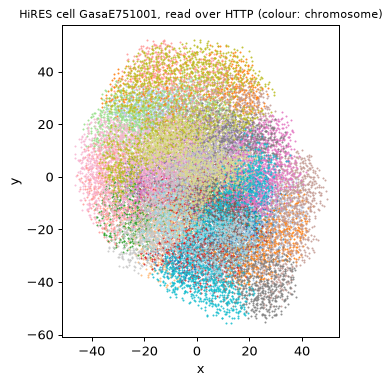

In [23]:
import fsspec.implementations.http  # noqa: F401  (import the HTTP filesystem first, so it is not timed)

hires_url = catalog["datasets"][[d["id"] for d in catalog["datasets"]].index("hires_embryo")]["url"]
t0 = time.perf_counter(); hires = ChromData.read(hires_url, backed=True); t_open = time.perf_counter() - t0
print(f"open {hires_url.rsplit('/', 1)[1]}: {t_open:.1f} s; {hires.n_spots:,} spots, {hires.n_cells:,} cells, "
      f"{atlas.loc['hires_embryo', 'size_mb'] / 1e3:.1f} GB")
cid = hires.cells.index[0]
t0 = time.perf_counter(); cell = hires.get_cell(cid, columns="coords"); t_cell = time.perf_counter() - t0
print(f"get_cell({cid!r}, columns='coords'): {t_cell:.1f} s, {cell.n_spots:,} particles in {cell.n_traces} traces "
      f"({hires.cells.loc[cid, 'stage']}, {hires.cells.loc[cid, 'cell_type']}; unit: {hires.uns.get('xyz_unit')})")
try:
    ChromData.read(hires_url)
except ValueError as err:
    print("ValueError:", err)

chrom = cell.spots["chrom"].astype(str).to_numpy()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for k, c in enumerate(cell.chroms):
    m = chrom == c
    ax.scatter(cell.coords[m, 0], cell.coords[m, 1], s=0.3, color=plt.cm.tab20(k % 20), rasterized=True)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(f"HiRES cell {cid}, read over HTTP (colour: chromosome)", fontsize=9)
plt.show()

`ds.atlas(id)` is `ChromData.read(<catalog url>, backed=True)`.  The Stevens 2017 store copied at the
start, read over HTTP: one cell equals the local read, and the store carries its maps embedded:

In [24]:
remote = ChromData.read(f"{DEFAULT_ATLAS}/stevens2017_mesc.chromdata.zarr", backed=True)   # = ds.atlas("stevens2017_mesc")
t0 = time.perf_counter(); r1 = remote.get_cell("Cell_1", columns="coords"); t = time.perf_counter() - t0
print(f"remote get_cell: {t:.1f} s; identical to the local store:",
      np.array_equal(r1.coords, cell1.coords) and r1.spots.equals(cell1.spots), "| embedded:", remote.embedded_links()["contacts"])

remote get_cell: 0.6 s; identical to the local store: True | embedded: {'bulk': 'bulk', 'per_cell': 'per_cell'}


`tracks=` works the same over HTTP: one Takei 2025 cerebellum cell with one of its 62 per-spot
immunofluorescence / RNA channels (out of a 2 GB store):

In [25]:
cereb = ChromData.read(f"{DEFAULT_ATLAS}/takei2025_cerebellum.chromdata.zarr", backed=True)
pk = cereb.cells.index[cereb.cells["cell_type"] == "Purkinje"][0]
t0 = time.perf_counter(); c = cereb.get_cell(pk, columns="coords", tracks=["H3K27ac"]); t = time.perf_counter() - t0
print(f"{len(cereb.track_names()['spot'])} spot tracks in the store; Purkinje cell {pk}: {c.n_spots:,} spots, "
      f"tracks {list(c.spot_tracks.columns)}, read in {t:.1f} s; H3K27ac median {c.spot_tracks['H3K27ac'].median():.2f}")

62 spot tracks in the store; Purkinje cell 1_0_26: 4,225 spots, tracks ['H3K27ac'], read in 0.9 s; H3K27ac median 0.46


Embedded contact maps read the same way: one scHiCAR cortex cell's chr1 contacts, and a region of the
merged map of all 5,313 cells.

In [26]:
from chromdata.embedded import open_all

schicar_url = f"{DEFAULT_ATLAS}/schicar_mouse_cortex.chromdata.zarr"
t0 = time.perf_counter(); maps = open_all(schicar_url); t_maps = time.perf_counter() - t0
pc, bulk = maps["per_cell"], maps["all_cells"]
print(f"open_all: {t_maps:.1f} s -> {len(maps)} maps; per_cell: {len(pc.cells):,} cells at {pc.resolutions} bp; "
      f"all_cells: {bulk.resolutions}")
t0 = time.perf_counter(); px = pc.cell_pixels("cis/chr1", [0]); t1 = time.perf_counter() - t0
t0 = time.perf_counter(); region = bulk.region_pixels("chr1", 0, 50, resolution=1_000_000); t2 = time.perf_counter() - t0
print(f"cell {pc.cells[0]} chr1: {px[:, 2].sum():,} contacts ({t1:.1f} s); "
      f"all cells, chr1 0-50 Mb at 1 Mb: {region[:, 2].sum():,} contacts ({t2:.1f} s)")

open_all: 0.3 s -> 24 maps; per_cell: 5,313 cells at [1000000] bp; all_cells: [250000, 500000, 1000000, 2000000]


cell ACGAACAAACTCAGACTT chr1: 3,724 contacts (0.4 s); all cells, chr1 0-50 Mb at 1 Mb: 1,881,607 contacts (0.4 s)


## Next steps

- `chromdata_basics` — the data model (bins, tracks, cells, intervals, results, cell positions).
- `import_fofct` — FOF-CT import / export.
- `tad_calling`, `loop_calling` — the ArcFISH callers, which stream over a backed store
  (`streaming=True`, the default on backed data) within `chromdata.settings.memory_budget`.
- The web browser (`uchrom_browser`) opens local stores and the atlas backed, the same way.